# Bài 2 (Trang 37, 38) - Online Retail (United Kingdom)
## Câu 11: Biểu diễn độ tin cậy, độ hỗ trợ của tập luật lên đồ thị phân tán

**Sinh viên:** Trần Đình Võ - **MSSV:** 6451071088

In [1]:
HO_TEN = "Trần Đình Võ"
MSSV = "6451071088"
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")

Họ tên: Trần Đình Võ - MSSV: 6451071088


### Import thư viện và đọc dữ liệu

In [2]:
import time
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
%matplotlib inline

df = pd.read_excel("../Dataset/Online Retail.xlsx")

### Các bước xử lý của câu 1 → 10 (chuẩn bị dữ liệu)

In [3]:
df["Description"] = df["Description"].str.strip()
df = df.dropna(axis=0, subset=["InvoiceNo"])
df["InvoiceNo"] = df["InvoiceNo"].astype(str)

df = df[~df["InvoiceNo"].str.contains("C")]

grouped = (df[df["Country"] == "United Kingdom"]
           .groupby(["InvoiceNo", "Description"])["Quantity"]
           .sum())

basket = grouped.unstack().reset_index().fillna(0).set_index("InvoiceNo")

def encode_units(x):
    return 1 if x >= 1 else 0

# Tương đương basket.map(encode_units) nhưng vector hóa cho nhanh; kiểu bool theo khuyến nghị của mlxtend
basket_sets = basket >= 1

basket_sets = basket_sets.drop(columns=["POSTAGE"], errors="ignore")

start = time.time()
frequent_itemsets = apriori(basket_sets, min_support=0.03, use_colnames=True)
apriori_time = time.time() - start

rules = association_rules(frequent_itemsets, num_itemsets=len(basket_sets),
                          metric="confidence", min_threshold=0.5)

rules["antecedents"] = rules["antecedents"].apply(lambda x: ", ".join(sorted(x)))
rules["consequents"] = rules["consequents"].apply(lambda x: ", ".join(sorted(x)))

### Câu 11: Biểu diễn độ tin cậy, độ hỗ trợ của tập luật lên đồ thị phân tán

In [4]:
support = rules["support"].values
confidence = rules["confidence"].values

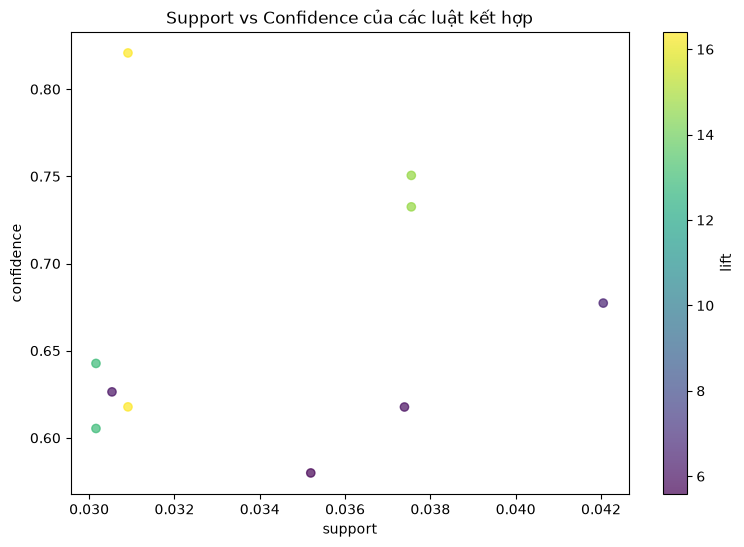

In [5]:
plt.figure(figsize=(9, 6))
plt.scatter(support, confidence, alpha=0.7, marker="o", c=rules["lift"], cmap="viridis")
plt.colorbar(label="lift")
plt.xlabel("support")
plt.ylabel("confidence")
plt.title("Support vs Confidence của các luật kết hợp")
plt.show()

### Nhận xét
- Các luật có support thấp (0.03-0.045) nhưng confidence khá cao (0.58-0.82); luật có lift cao thể hiện mối liên hệ mạnh giữa hai vế.